In [3]:
import pandas as pd
import matplotlib.pyplot as plt
archivo = 'C:/Users/USER/Desktop/PORTAFOLIO/Practicando Python/datos/VENTAS_FUNCIONES.xlsx'

In [4]:
df = pd.read_excel(archivo, sheet_name='Ventas_final')
df.head()

,ID_Venta,Fecha,ID_Cliente,ID_Producto,Producto,Categoria,Cantidad,Precio_unitario,Descuento,Tipo_pago,ID_Vendedor,Sucursal,Venta_Total
0,V-0001,2025-09-09,C-001,P-003,Smart Watch,Electrónica,13,200,0.1,Tarjeta,V-005,Ayacucho,2340.0
1,V-0002,2025-12-18,C-001,P-004,Smart Phone,Telefonía,34,800,0.2,Efectivo,V-005,Ayacucho,21760.0
2,V-0003,2025-08-26,C-003,P-001,Audífonos,Electrónica,5,50,0.1,Transferencia,V-001,Lima,225.0
3,V-0004,2025-03-16,C-002,P-001,Audífonos,Electrónica,15,50,0.1,Transferencia,V-003,Arequipa,675.0
4,V-0005,2025-02-06,C-003,P-002,Laptop,Computo,44,1200,0.3,Tarjeta,V-004,Moquegua,36960.0


In [5]:
# Análisis descriptivo
df["Venta_Total"].describe() # Descripción general del las ventas totales
print(df.groupby("Producto")["Venta_Total"].mean()) # Promedio de ventas totales por Producto


Producto
Audífonos       1135.417323
Laptop         21228.000000
Smart Phone    15880.748576
Smart Watch     4495.358582
Name: Venta_Total, dtype: float64


<Axes: xlabel='Fecha'>

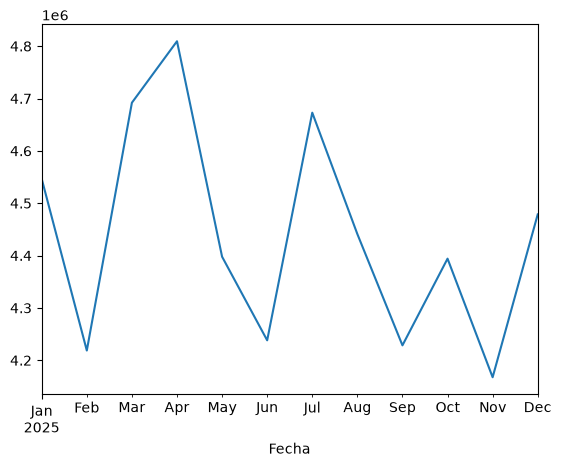

In [6]:
# Análisis temporal
df["Fecha"] = pd.to_datetime(df["Fecha"])
ventas_mensuales = df.groupby(df["Fecha"].dt.to_period("M"))["Venta_Total"].sum()
ventas_mensuales.plot()


In [7]:
# Comparando categóricas
print(pd.pivot_table(df, values="Venta_Total", index="Categoria",
                     columns="Tipo_pago", aggfunc="sum"))

Tipo_pago     Efectivo    Tarjeta  Transferencia
Categoria                                       
Computo      9360960.0  8715000.0      8671320.0
Electrónica  2158920.0  2368620.0      2493180.0
Telefonía    6563200.0  6483200.0      6471040.0


In [8]:
# Correlaciones entre variables
df[["Cantidad", "Precio_unitario", "Descuento", "Venta_Total"]].corr()

,Cantidad,Precio_unitario,Descuento,Venta_Total
Cantidad,1.000000,0.000916,0.003557,0.487064
Precio_unitario,0.000916,1.000000,0.985405,0.788074
Descuento,0.003557,0.985405,1.000000,0.766199
Venta_Total,0.487064,0.788074,0.766199,1.000000


In [9]:
from scipy import stats
lima = df[df["Sucursal"]=="Lima"]["Venta_Total"]
arequipa = df[df["Sucursal"]=="Arequipa"]["Venta_Total"]
stats.ttest_ind(lima, arequipa)


TtestResult(statistic=np.float64(-0.7119307745474124), pvalue=np.float64(0.4765897340334173), df=np.float64(2023.0))

In [12]:
# Modelo Simple
from sklearn.linear_model import LinearRegression
X = df[["Cantidad", "Precio_unitario", "Descuento"]]
y = df["Venta_Total"]
modelo = LinearRegression().fit(X, y)
print(modelo.coef_, modelo.intercept_)


[ 4.30312410e+02  2.64676990e+01 -5.02409097e+04] -6200.278171620183
